# Results {#sec-results}

In this section, we show how we obtain our results. The figures shown here are the main and supplementary figures in our article. The key results can be summarized as follows:
* The influence of optimism on performance in a two-armed bandit task is modulated by resource scarcity
* Optimism increases risk-seeking in a risk-reward dilemma
* Optimism enhances cooperation in a stag-hunt game
* Optimism/pessimism has no effect on cooperation in a prisoner's dilemma

First, we import what we need.

In [1]:
# general imports

import numpy as np
from scipy.stats import norm

import jax.numpy as jnp
from jax import jit
from functools import partial

import matplotlib.pyplot as plt
import matplotlib as mpl

import pandas as pd
import seaborn as sns

In [2]:
# pyCRLD imports

# Agents
from pyCRLD.Agents.Base import abase
from pyCRLD.Agents.StrategySARSA import stratSARSA

# Environment
from pyDDRL.Environments.TwoArmedBandit import TwoArmedBandit

# Utilities
from pyCRLD.Utils.Helpers import *
from pyDDRL.Utils.Trajectories1D import trajectories_1D 
from pyDDRL.Utils.PhasePlot import phaseplot, _data_to_plot, _strategies, _dXisa_s
from pyDDRL.Utils.PlottingTools import *

In [3]:
# DDRL imports

from pyDDRL.Agents.DDRLBase import DDRLBase
from pyDDRL.Agents.DDRLSarsa import DDRLSarsa

We want to study the effect of optimism/pessimism in a two-armed bandit task. To do so, we define functions that help us visualize 
* the phase plots for varying levels of optimism/pessimism
* the deterministic strategies over time for varying levels of optimism/pessimism
* the average payoff collected over time for varying levels of optimism/pessimism.

### Influence of optimism/pessimism on performance in a poor environment

In a "poor" two-armed bandit task, rewards are scarce. We thus define a two-armed bandit task with $p_1 = 0.3$, and $p_2 = 0.1$.

In [4]:
# Poor environment

xs = np.array([[-1, 1],
               [-1, 1]])
ps = np.array([[0.7, 0.3],
               [0.9, 0.1]])
env = TwoArmedBandit(disttype='discrete', xs=xs, ps=ps)

Now, we can plot the phase plot, strategy over time, and reward over time, of an agent which performs this task. We compare several levels of optimism and pessimism. These levels are defined by the upper weights $w_U$ - that is, the weights the agent applies to the upper part of the distribution.

In [5]:
# List of weight values to compare
weights = np.array([0.1, 0.2, 0.4, 0.8, 1., 2., 4., 8., 10.])

# i,s,a to plot along the x-axis
x = ([0], [0], [0]) 

# Range and resolution of X
res = np.linspace(0, 1., 21) 
res[0] = 0.0001
res[-1] = 0.9999

In Section @sec-calibration, we found that the discretization sigma yielding the lowest error for a neutral agent on a two-armed bandit task is $\sigma=0.0001$. We therefore use it to compute our results.

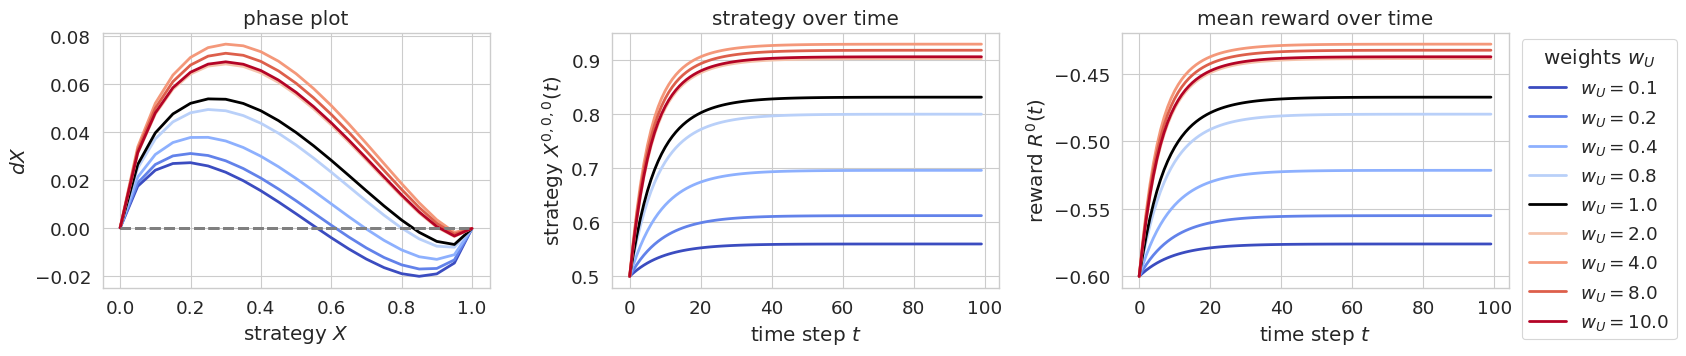

In [6]:
compare_levels(env, weights, gamma=0., beta=4., Rmin=-1, Rmax=1, 
               xinds=x, res=res, nrb=29, discsig=0.0001, traj_len=100, 
               cmap='coolwarm', save=True, 
               savename='../figs/TwoArmedPoorPhasePlot.png')

### Influence of optimism/pessimism on performance in a rich environment

In a "rich" two-armed bandit task, rewards are abundant. We thus define a two-armed bandit task with $p_1 = 0.9$, and $p_2 = 0.7$.

In [7]:
# Rich environment

xs = np.array([[-1, 1],
               [-1, 1]])
ps = np.array([[0.1, 0.9],
               [0.3, 0.7]])
env = TwoArmedBandit(disttype='discrete', xs=xs, ps=ps)

Now, we can plot the phase plot, strategy over time, and reward over time, of an agent performing the rich task. We compare the same levels of optimism and pessimism as above.

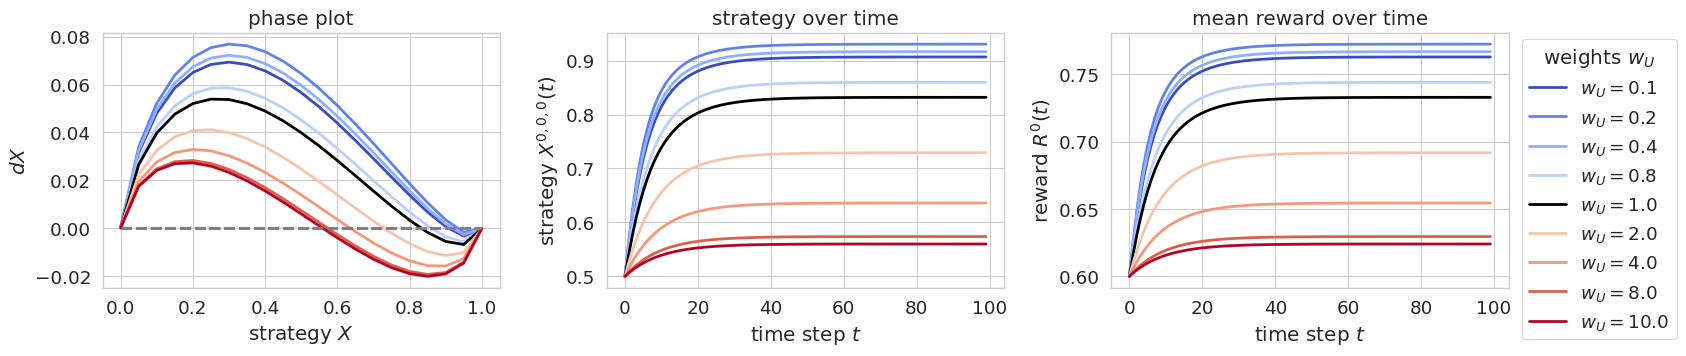

In [8]:
compare_levels(env, weights, gamma=0., beta=4., Rmin=-1, Rmax=1, 
               xinds=x, res=res, nrb=29, discsig=0.0001, traj_len=100, 
               cmap='coolwarm', save=True, 
               savename='../figs/TwoArmedRichPhasePlot.png')

### Comparison between the three DDRL biasing methods and asymmetric RL

Asymmetric RL was previously used to model optimism and pessimism in simple RL algorithms. It postulates a pair of asymmetric learning rates: a learning rate $\alpha^{+}$ that updates positive prediction errors, and a rate $\alpha^{-}$ that updates negative prediction errors. The bias strength $b$ is defined by the learning-rates ratio: 

$$ b = \frac{\alpha^{+}}{\alpha^{-}} $$

Cazé and Van der Meer (2013) have shown that, for an agent with bias strength $b$, the Q-value at steady-state of arm $a_{i}$ is:

$$ Q^{a_i}_{\infty} = \frac{p_{a_i} \cdot b - (1 - p_{a_i})}{p_{a_i} \cdot b + (1 - p_{a_i})} $$

Below, we compare the final strategies obtained with the three DDRL biasing methods (quantile, expectile, weights) against the final strategies obtained with asymmetric RL.

Now, we create lists of bias strengths, quantiles, expectiles and weights. 

The list of bias strengths is:

In [4]:
b_pes = np.linspace(0.1, 1., 10)  # pessimistic values
b_opt = np.linspace(1., 10., 10)  # optimistic values
b_ratios = np.zeros((19))
b_ratios[:9] = b_pes[:9]
b_ratios[9:] = b_opt
b_ratios

array([ 0.1,  0.2,  0.3,  0.4,  0.5,  0.6,  0.7,  0.8,  0.9,  1. ,  2. ,
        3. ,  4. ,  5. ,  6. ,  7. ,  8. ,  9. , 10. ])

Rowland *et al.* (2021) showed that, in stateless environments, expectile-based distributional RL is equivalent with asymmetric RL, when $\tau = \frac{b}{b+1}$.

We want to investigate whether this is the case on a two-armed bandit task, so we define the expectile list as:

In [5]:
e_list = b_ratios / (b_ratios + 1)
e_list

array([0.09090909, 0.16666667, 0.23076923, 0.28571429, 0.33333333,
       0.375     , 0.41176471, 0.44444444, 0.47368421, 0.5       ,
       0.66666667, 0.75      , 0.8       , 0.83333333, 0.85714286,
       0.875     , 0.88888889, 0.9       , 0.90909091])

Next, we define a quantile list with $\tau$ spanning the range of $[0,1]$:

In [6]:
q_list = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30,
          0.35, 0.40, 0.45, 0.50, 0.55, 0.60,
          0.65, 0.70, 0.75, 0.80, 0.85, 0.90,
          0.95]

Finally, we use a similar list for the upper weights $w_U$ as the one we used for the bias strengths $b$:

In [7]:
w_pes = np.linspace(0.1, 1., 10)
w_opt = np.linspace(1., 10., 10)
w_list = np.zeros((19))
w_list[:9] = w_pes[:9]
w_list[9:] = w_opt
w_list

array([ 0.1,  0.2,  0.3,  0.4,  0.5,  0.6,  0.7,  0.8,  0.9,  1. ,  2. ,
        3. ,  4. ,  5. ,  6. ,  7. ,  8. ,  9. , 10. ])

We can now compute and plot our comparisons on a poor two-armed bandit task:

In [8]:
# Compute comparisons in poor env
b_xinf, q_xinf, e_xinf, w_xinf = compute_comparisons(0.3, 0.1, b_ratios, q_list, e_list, 
                                                     w_list, gamma=0, beta=4, Rmin=-1, 
                                                     Rmax=1, nrb=29, discsig=0.0001, lr=0.1)

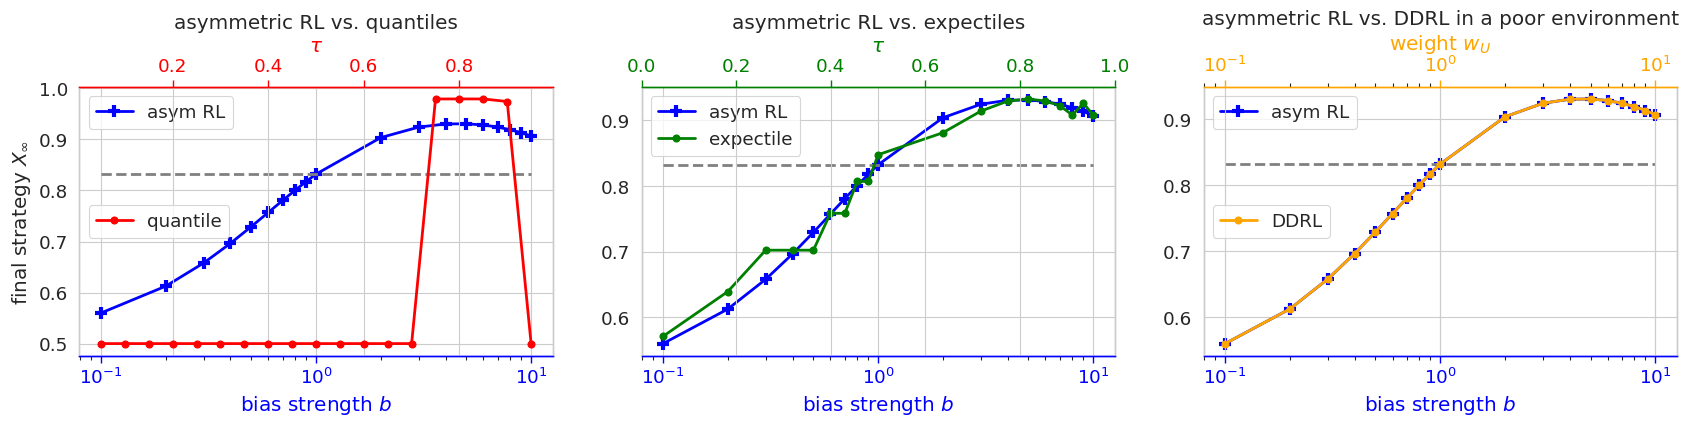

In [9]:
# Plot comparisons in poor env
plot_comparisons(b_ratios, q_list, e_list, w_list, b_xinf, 
                 q_xinf, e_xinf, w_xinf, scarcity="poor",
                 save=True, savename='../figs/TwoArmedMethodComparisonPoor.png')

And now, in a rich environment:

In [10]:
# Compute comparisons in a rich environment
b_xinf, q_xinf, e_xinf, w_xinf = compute_comparisons(0.9, 0.7, b_ratios, q_list, e_list, 
                                                     w_list, gamma=0, beta=4, Rmin=-1, 
                                                     Rmax=1, nrb=29, discsig=0.0001, lr=0.1)

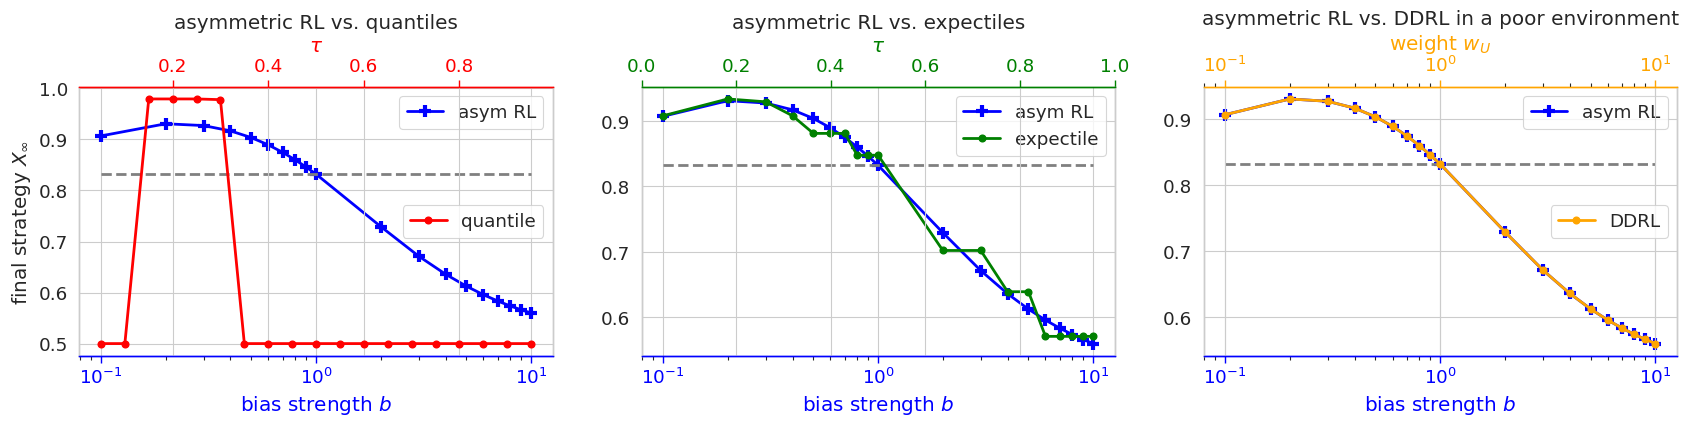

In [11]:
# Plot comparisons in a rich environment
plot_comparisons(b_ratios, q_list, e_list, w_list, b_xinf, 
                 q_xinf, e_xinf, w_xinf, scarcity="rich",
                 save=True, savename='../figs/TwoArmedMethodComparisonRich.png')